## Linear Regression

Linear regression is an approach we use to model the relationship between a scalar dependent variable y and one or more explanatory variables (aka independent variables) denoted by X. In machine learning parlance, these explanatory variables or predictors are called features and target or the dependent variable labels. Regression modesl are models which predict a continuous outcome.

### Univariate Regression

The simplest possible relationship between two variables is a univariate regression when there is only one feature to be explained.

$y_i \thickapprox  w_0 + w_1$

If we can measure some $(x_i,y_i)$ pairs, we could calculate our model parameters $w_0$ and $w_ 1$
Then we could predict y in the future based on x, or even try to influence y in the future by controlling x. This is achieved by minimizing the mean squared error,

In [ ]:
Image.open(os.path.join(dir_path,'Univariate.PNG'))

## Multivariate Regression

If there multiple features that are to be mapped to a target variable, then it is a multivariate regression problem.

$y_i \thickapprox  w_0 + w_1x_1 + w_2x_2 + \cdots+ w_nx_n $ 

or more generally 

$y_i \thickapprox  \sum \limits_{j} w_ix_{ij} $, where ilabels different observations and j labels different features.


## Workflow

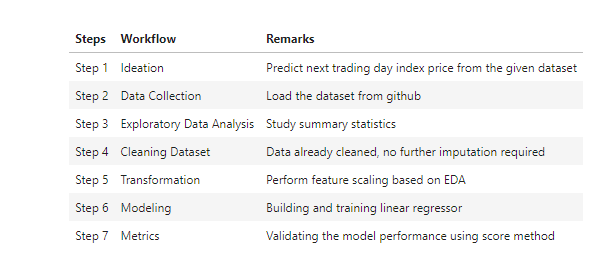

In [3]:
Image.open(os.path.join(dir_path,'ML_workflow.PNG'))

### import libraries

In [2]:
# import libraries

# data manipulation
import pandas as pd
import numpy as np

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# data preprocessing
# scikit learn(sklearn) package is used primarily for machine learning
# model selection ---> pre procesing --> pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline

# regressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet

# evaluation metrics
from sklearn.metrics import mean_squared_error

# float display
pd.options.display.float_format = '{:0.2f}'.format

# system
import os

# ignore warnings
import warnings
warnings.filterwarnings('ignore')

from PIL import Image

dir_path = r"C:\Users\Admin\Desktop\CQF Course\Module 4\Python Labs\Introduction to Machine Learning using Scikit-learn"


## Data collection

In [ ]:

path = os.path.join(dir_path,'niftyindex.csv')
df = pd.read_csv(path,index_col = 0, dayfirst=True)          # dayfirst DD/MM format

## EDA (Exploratory Data Analysis)

In [ ]:
df.describe()

## Cleaning DataSet

In [ ]:
df.isnull().sum()

## Feature Engineering

Features are also known as an independent variable which are used to determine the value of the target variable. We will create features and target (label) from the raw dataset.

In [ ]:
def create_features(frame):
    
    df = frame.copy()
    multiplier = 2

    df['OC'] = df['Close']/df['Open'] -1                                    # open Close
    df['HL'] =  df['High']/df['Low'] -1                                     # high low
    df['GAP'] = df['Open']/df['Close'].shift(periods =1) -1                 # gap up/down, shift() 
    df['RET'] = np.log(df['Close']/df['Close'].shift(periods =1))           # log return = log(Pi/Pi-1)

    df['RET3']= df['RET'].rolling(window =3).sum()                          # rolling() - 3 days rolling window including that day
    df['MA3'] = df['Close']/df['Close'].rolling(3).mean()
    df['OC3'] = df['OC'].rolling(3).mean()
    df['HL3'] = df['HL'].rolling(3).mean()
    df['GAP3'] = df['GAP'].rolling(3).mean()
    df['STD3'] = df['RET'].rolling(3).std()
    df['UB3'] = df['Close'].rolling(3).mean() + df['Close'].rolling(3).std()*multiplier  # bolinger band
    df['LB3'] = df['Close'].rolling(3).mean() - df['Close'].rolling(3).std()*multiplier
    
    df['Label'] = df['Close'].shift(-1)

    # dropping NA values
    df.dropna(inplace = True)
    
    return df

## Feature Specification

Features or Predictors are also known as an independent variable which are used to determine the value of the target variable. We will derive a features set from the original dataset.

In [ ]:
df = create_features(df)

# drop OHLCV and 'Label'
X = df.drop(columns = ['Open','High','Low','Close','Volume','Label'])


## Label Definition

Label or the target variable is also known as the dependent variable. Here, the target variable is the closing price of the index the next trading day.

In [ ]:
y = np.array(df['Label'])

## Feature Selction

Reduce the number of input variables that are believed to be most useful to a model. We use correlation measures which is one the filter methods to address multicollinearity among features.

In [ ]:
# 'annot_kws' param to change font size of annotations
plt.figure(figsize =(20,10))
sns.heatmap(X.corr(),annot= True,cmap = 'coolwarm', fmt ='0.2f',cbar = True, annot_kws={"size": 11})
plt.title('Features Set Correlations')
plt.show()


X.drop(columns = 'LB3', inplace = True)
feature_names = X.columns

## Feature Scaling

The choice of scaling techniques to be used should come from the Exploratory Data Analysis of features set.

In [ ]:
# will be handled in Regression Class
# required because features dont have same scale

plt.figure(figsize =(20,10))
sns.boxplot(data = pd.melt(X), x = 'variable', y= 'value')

## Regression Class

We'll now create a Regression class for linear estimators : Linear, Lasso, Ridge and ElasticNet

In [ ]:
# pipeline - Sequentially apply a list of transforms and a final estimator.Intermediate steps of the pipeline must be 
# 'transforms', that is, they must implement `fit` and `transform` methods.

class Regression:
    
    def __init__(self, X,y,test_size =0.2):
        self.X = X
        self.y=y
        self.test_size = test_size
        
        # split training and testing dataset
        # train_test_split() 
        # random_state -Controls the shuffling applied to data before applying split. Pass an int for reproducible output
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(self.X, self.y, test_size =self.test_size,
                                                                                shuffle=False,random_state = 0)
    
    # pipeline, fit and predict
    def fit_predict(self, estimator, transformer, alpha = None, l1_ratio = None):
        try:
            model = Pipeline([('scaler',transformer),('regressor',estimator)])            # pipeline() - model : pipeline object
            model.fit(self.X_train,self.y_train)                                          # model.fit()
            y_pred = model.predict(self.X_test)                                           # model.predict()
        
        except Exception as e:
            print(str(e))
        
        # had we passed model = LinearRegression(), then model.coef_, model.intercept_
        
        return model, model['regressor'].intercept_, model['regressor'].coef_, y_pred     # intercept_, coef_
    
    # evaluate metrics
    def eval_metrics(self, model,y_pred):
        mse = mean_squared_error(self.y_test,y_pred, squared=True)                     # mean_squared_error() 
        rmse = mean_squared_error(self.y_test,y_pred, squared=False)              
        r2_train = model.score(self.X_train, self.y_train)                             # model.score()
        r2_test = model.score(self.X_test, self.y_test)
        
        return mse, rmse,r2_train, r2_test

    # plot coefficients as function of lambda
    def plot_coeff(self,model_name):
        coef = []
        alpha_range = np.logspace(2,-2,200)            # np.logspace() -evenly distribute numbers in log scale (10^x default base 10)
        
        if model_name == 'Lasso':
            for i in alpha_range:
                coef.append(self.fit_predict(Lasso(alpha = i,random_state =0),MinMaxScaler())[2])
 
        if model_name == 'Ridge':
            alpha_range = np.logspace(6, -2, 200)
            for i in alpha_range:
                coef.append(self.fit_predict(Ridge(alpha = i,random_state =0),MinMaxScaler())[2])
                
        if model_name == 'ElasticNet':
            for i in alpha_range:
                coef.append(self.fit_predict(ElasticNet(alpha = i,random_state =0),MinMaxScaler())[2]) 
                
        # plot coefficients
        plt.figure(figsize= (20,10)) 
        plt.plot(alpha_range,coef)
        plt.xscale('log')                        # plt.xscale()
        plt.legend(feature_names)                # plt.legend()
        plt.xlabel('$\lambda$')                  # laTeX notation
        plt.ylabel('$\mathbf{w}$')               # laTeX notation
        plt.title('{} : coefficients as a function of the regularization'.format(model_name))    
        
        return plt.show()

## Linear Regression

In linear regression, the model coefficients are selected by minimizing a loss function. First, we instantiate the class object and pass the estimator and transformer to fit and predict the model.

In [ ]:
lr = Regression(X,y)  # initialize the class object, simialr to lr = LinearRegression() : initialize the linear regressor

lr_model , lr_intercept, lr_coef, lr_y_pred = lr.fit_predict(LinearRegression(), MinMaxScaler())
lr_model , lr_intercept, lr_coef, lr_y_pred

# Regularized Regression
If the coeficients are too large in linear regression, it can lead to overfitting the model. We do regularization to over come such issues that penalises large coefficients. Lasso and Ridge regression are penalty regression that prevent over-fitting from the simple linear regression.

## Lasso

The Least Absolute Shrinkage and Selection Operator (LASSO) is a variation of linear regression. In Lasso, the loss function is minimized by limiting the sum of absolute values of the model coefficients where the L1 penalty term is added to the Mean Square Error (MSE). The L1 penalty term not only shrinks the coefficents, but shrinks some of them to zero and that is very useful for feature selection. where, λ is the regularization penalty.

In [ ]:
Image.open(os.path.join(dir_path,'Lasso.PNG'))

In [ ]:
lasso = Regression(X,y)

lasso_model , lasso_intercept, lasso_coef, lasso_y_pred = lasso.fit_predict(Lasso(alpha=0.3, random_state=0), MinMaxScaler())
lasso_model , lasso_intercept, lasso_coef, lasso_y_pred

In [ ]:
# plot coefficients
lasso.plot_coeff('Lasso')

## Ridge

In ridge regression, the cost function is altered by adding a L2 penality equivalent to square of the magnitude of the coefficients. The Ridge regression shrinks the coefficients and helps to reduce the multi-collinearity. As seen from the above graph, when λ→0, the cost function becomes similar to the linear regression cost function.

In [ ]:
Image.open(os.path.join(dir_path,'Ridge.PNG'))

In [ ]:
ridge = Regression(X,y)

ridge_model , ridge_intercept, ridge_coef, ridge_y_pred = ridge.fit_predict(Ridge(alpha=1, random_state=0), MinMaxScaler())
ridge_model , ridge_intercept, ridge_coef, ridge_y_pred

In [ ]:
# plot coefficients
ridge.plot_coeff('Ridge')

## ElasticNet Regressor

ElasticNet combines the properties of both Lasso and Ridge regression. It penalizes the model using both the L1 and L2 norm.

In [ ]:
Image.open(os.path.join(dir_path,'ElasticNet.PNG'))

where 
0 ≤ α ≤ 1. Elastic net is same as lasso when α=1 and ridge when α=0. For other values of αthe penalty term interpolate between L1 and L2 norm of the coefficient.

In [ ]:
elasticnet = Regression(X,y)

elasticnet_model , elasticnet_intercept, elasticnet_coef, elasticnet_y_pred = elasticnet.fit_predict(ElasticNet(alpha=0.1, l1_ratio=1e-10, random_state=0), MinMaxScaler())
elasticnet_model , elasticnet_intercept, elasticnet_coef, elasticnet_y_pred

In [ ]:
# plot coefficients
elasticnet.plot_coeff('ElasticNet')

## Model Comparisions based on MSE, R2

In [ ]:
# comparing model coefficients
df_coef = pd.DataFrame({
    'LR':lr_coef,
    'Lasso':lasso_coef,
    'Ridge':ridge_coef,
    'ElasticNet':elasticnet_coef
},index = feature_names)

df_coef                      

In [ ]:
# comparing evaluation metrics 
eval_df = pd.DataFrame({
    'LR': lr.eval_metrics(lr_model, lr_y_pred),
    'Lasso': lasso.eval_metrics(lasso_model, lasso_y_pred),
    'Ridge': ridge.eval_metrics(ridge_model, ridge_y_pred),
    'ElasticNet': elasticnet.eval_metrics(elasticnet_model, elasticnet_y_pred)
}, index = ['MSE', 'RMSE', 'R2_train', 'R2_test'])

eval_df

## References

[Scikit Learn Documentation](https://scikit-learn.org/stable/index.html) 

[Scikit Learn API Reference](https://scikit-learn.org/stable/modules/classes.html)